# Экзамен. Демченко Ирина MAF'28


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from rink import plot_rink

sns.set_theme(style='whitegrid')
pd.set_option('display.precision', 3)
pd.set_option('display.max_rows', 20)


## 1. Загрузка данных


In [2]:
events = pd.read_excel('NHL-playoffs-2026.xlsx', index_col=0, parse_dates=['Date'])
G = 'Game ID'
T = 'Team Making the Play'
P1, P2, P3 = [f'Player in the Event #{i}' for i in (1, 2, 3)]
X, Y = 'X Coordinate on the Ice Rink', 'Y Coordinate on the Ice Rink'
SIDE = "Home Team's Defending Side"
away_ice = [f"Away Team's Player on the Ice #{i}" for i in range(1, 7)]
home_ice = [f"Home Team's Player on the Ice #{i}" for i in range(1, 7)]
AG, HG = "Away Team's Goalie", "Home Team's Goalie"

print('Размер:', events.shape)
display(events.iloc[:10, [2, 3, 4, 9, 12]])


Размер: (29710, 38)


,Date,Away Team,Home Team,Remaining Time,Play Type
0,2026-04-19,Boston Bruins,Buffalo Sabres,20:00,period-start
1,2026-04-19,Boston Bruins,Buffalo Sabres,20:00,faceoff
2,2026-04-19,Boston Bruins,Buffalo Sabres,19:47,hit
3,2026-04-19,Boston Bruins,Buffalo Sabres,19:46,hit
4,2026-04-19,Boston Bruins,Buffalo Sabres,19:41,hit
5,2026-04-19,Boston Bruins,Buffalo Sabres,19:27,hit
6,2026-04-19,Boston Bruins,Buffalo Sabres,19:03,hit
7,2026-04-19,Boston Bruins,Buffalo Sabres,18:53,missed-shot
8,2026-04-19,Boston Bruins,Buffalo Sabres,18:48,hit
9,2026-04-19,Boston Bruins,Buffalo Sabres,18:37,missed-shot


Читаем Excel. Сохранённые номера строк используем как индекс, а поле Date сразу преобразуем в даты. Каждая строка описывает одно событие матча.

**Вывод:** Загружены 29 710 событий и 38 полей.


## 2. Сводка по матчам


In [3]:
grouped = events.groupby(G)
games = grouped.agg(**{
    'Date': ('Date', 'first'), 'Away Team': ('Away Team', 'first'),
    'Home Team': ('Home Team', 'first'),
    'Away Score': ('Cumulated Away Score', 'max'),
    'Home Score': ('Cumulated Home Score', 'max')})
score_cols = ['Away Score', 'Home Score']
overtimes = (grouped['Period'].max() - 3).rename('Overtimes')
games['Outcome'] = overtimes.map(lambda n: 'Final' if n == 0 else ('Final/OT' if n == 1 else f'Final/{n}OT'))
display(games.tail())
display(overtimes.value_counts().sort_index().rename('Число матчей'))
goal_counts = events.loc[events['Play Type'].eq('goal')].groupby(G).size().reindex(games.index, fill_value=0)
assert goal_counts.eq(games[score_cols].sum(axis=1)).all(), 'События goal расходятся со счётом'


,Date,Away Team,Home Team,Away Score,Home Score,Outcome
Game ID,,,,,,
2025030412,2026-06-04,Vegas Golden Knights,Carolina Hurricanes,3,4,Final/OT
2025030413,2026-06-06,Carolina Hurricanes,Vegas Golden Knights,4,5,Final/2OT
2025030414,2026-06-09,Carolina Hurricanes,Vegas Golden Knights,5,3,Final
2025030415,2026-06-11,Vegas Golden Knights,Carolina Hurricanes,2,4,Final
2025030416,2026-06-14,Carolina Hurricanes,Vegas Golden Knights,3,0,Final


Overtimes
0    60
1    18
2     4
Name: Число матчей, dtype: int64

Группируем события по Game ID. Из первой строки каждого матча берём дату и команды, а максимум накопленного счёта даёт итоговые голы. Число овертаймов — максимальный номер периода минус три. Поле Outcome различает основное время, один и несколько овертаймов.

**Вывод:** Всего 82 матча: 60 завершились в основное время, 18 — в первом овертайме и 4 — во втором.


## 3. Описание матча


In [4]:
def gameInfo(gameId):
    game = games.loc[gameId]
    return (f"{game['Home Team']} - {game['Away Team']} "
            f"({game['Home Score']} - {game['Away Score']}, {game['Outcome']}, {game['Date']:%Y-%m-%d})")

print(gameInfo(games.index.min()))
print(gameInfo(games.index.max()))


Buffalo Sabres - Boston Bruins (4 - 3, Final, 2026-04-19)
Vegas Golden Knights - Carolina Hurricanes (0 - 3, Final, 2026-06-14)


Функция gameInfo() находит матч по ID и возвращает строку с командами, счётом, исходом и датой. Порядок команд и счёта одинаковый: сначала хозяева, затем гости. Ниже эта функция используется для вывода найденных матчей.


## 4. Число голов за матч


In [5]:
games['Total Score'] = games['Away Score'] + games['Home Score']
display(games['Total Score'].describe())


count    82.000
mean      5.927
std       2.260
min       1.000
25%       5.000
50%       6.000
75%       7.000
max      15.000
Name: Total Score, dtype: float64

Складываем голы хозяев и гостей в Total Score и вызываем describe(). Статистика считается по матчам: каждый учитывается один раз.

**Вывод:** Среднее число голов — 5,927, медиана — 6, стандартное отклонение — 2,260. Минимум — 1 гол, максимум — 15; первый и третий квартили — 5 и 7.


## 5. Распределение числа голов


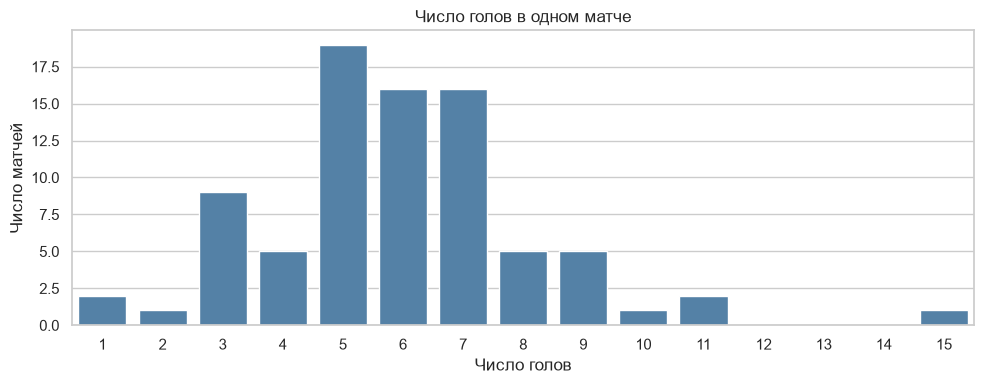

In [6]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.countplot(
    data=games, x='Total Score',
    order=range(games['Total Score'].min(), games['Total Score'].max() + 1),
    color='steelblue', ax=ax
)
ax.set(xlabel='Число голов', ylabel='Число матчей', title='Число голов в одном матче')
plt.tight_layout()
plt.show()


На горизонтальной оси — число голов, на вертикальной — число матчей с таким результатом. Сохраняем все целые значения от минимума до максимума, включая результаты, которых не было.

**Вывод:** Самый частый результат — 5 голов, так закончились 19 игр. От 5 до 7 голов включительно забили в 51 из 82 матчей, то есть примерно в 62%. Очень результативные матчи встречаются редко; максимум — 15 голов.


## 6. Самые результативные и нерезультативные матчи


In [7]:
low_games = games.index[games['Total Score'].eq(games['Total Score'].min())]
high_games = games.index[games['Total Score'].eq(games['Total Score'].max())]
print('Минимум:')
display([gameInfo(i) for i in low_games])
print('Максимум:')
display([gameInfo(i) for i in high_games])


Минимум:


['Montréal Canadiens - Tampa Bay Lightning (0 - 1, Final/OT, 2026-05-01)',
 'Philadelphia Flyers - Pittsburgh Penguins (1 - 0, Final/OT, 2026-04-29)']

Максимум:


['Colorado Avalanche - Minnesota Wild (9 - 6, Final, 2026-05-03)']

Выбираем все матчи с минимальным и максимальным числом голов и выводим их описания через gameInfo(). Один результат может принадлежать нескольким играм.

**Вывод:** Минимум — 1 гол: Montréal Canadiens — Tampa Bay Lightning (0:1) и Philadelphia Flyers — Pittsburgh Penguins (1:0), оба матча завершились в овертайме. Максимум — Colorado Avalanche — Minnesota Wild (9:6), всего 15 голов.


## 7. Число участников матча


In [8]:
player_columns = [*away_ice, *home_ice, AG, HG]
players = events.melt(id_vars=G, value_vars=player_columns, value_name='Player')
player_games = players[[G, 'Player']].dropna().drop_duplicates()
player_counts = player_games.groupby(G).size()
max_players = pd.DataFrame({
    'Game Info': [gameInfo(i) for i in games.index],
    'Player Count': player_counts
}, index=games.index)
display(max_players.loc[max_players['Player Count'].eq(player_counts.max())])


,Game Info,Player Count
Game ID,,
2025030216,"Montréal Canadiens - Buffalo Sabres (3 - 8, Fi...",40


Метод melt() собирает имена из всех колонок игроков на льду и обеих колонок вратарей в одну колонку Player. Удаляем пропуски и повторы пары «матч — игрок», затем считаем участников по матчам. Таблица player_games понадобится для средних показателей игроков.

**Вывод:** Максимум — 40 игроков в матче Montréal Canadiens — Buffalo Sabres (3:8), ID 2025030216: по 20 у каждой команды, включая четырёх вратарей. В PDF указано 41. Такое число получается, если включить NaN в уникальные значения: все пустые ячейки добавляют одну категорию. Это не дополнительный игрок с неизвестным именем, поэтому считаем только непустые имена и оставляем 40; включение NaN — возможная причина расхождения.


## 8. Расстояние броска до ворот


In [9]:
accurate_types = ['shot-on-goal', 'goal']
unblocked_types = accurate_types + ['missed-shot']
all_shot_types = unblocked_types + ['blocked-shot']

def distance_to_goal(x, y, goal_x):
    dx = x - goal_x
    dy = np.maximum(np.abs(y) - 3, 0)
    return np.hypot(dx, dy)

shots = events.loc[events['Play Type'].isin(unblocked_types)].copy()
assert shots[SIDE].isin(['left', 'right']).all(), 'Неизвестная сторона защиты'
assert (shots[T].eq(shots['Home Team']) | shots[T].eq(shots['Away Team'])).all(), 'Неизвестная команда бросающего'
assert shots[[X, Y]].notna().all().all(), 'Не хватает координат бросков'
is_home = shots[T].eq(shots['Home Team'])
home_defends_left = shots[SIDE].eq('left')
shots['Goal X'] = np.where(is_home.eq(home_defends_left), 89, -89)
shots['Shot Length'] = distance_to_goal(shots[X], shots[Y], shots['Goal X'])
shots['Shot'] = np.where(shots['Play Type'].isin(accurate_types), 'on goal', 'missed')
events['Shot Length'] = np.nan
events.loc[shots.index, 'Shot Length'] = shots['Shot Length']
display(shots[[G, 'Play Type', 'Shot Length']])


,Game ID,Play Type,Shot Length
7,2025030111,missed-shot,12.207
9,2025030111,missed-shot,12.000
12,2025030111,missed-shot,29.411
13,2025030111,shot-on-goal,62.169
19,2025030111,missed-shot,52.924
...,...,...,...
29695,2025030416,missed-shot,54.083
29696,2025030416,missed-shot,5.099
29704,2025030416,goal,46.239
29706,2025030416,missed-shot,60.926


Определяем атакуемые ворота по команде бросающего и стороне защиты хозяев. Если хозяева защищают левые ворота, они атакуют правые, а гости — левые; при другой стороне направления меняются. Координата X ворот равна 89 или −89 футам, а створ занимает отрезок от −3 до 3 по Y. До ближайшей точки створа считаем горизонтальное расстояние и, при необходимости, расстояние по вертикали до штанги; hypot() объединяет их.

**Вывод:** Расстояния в футах рассчитаны для всех 7 266 незаблокированных бросков: бросков в створ, голов и промахов. Измеряем расстояние до ближайшей точки створа, а не до центра ворот.


## 9. Распределения длины бросков


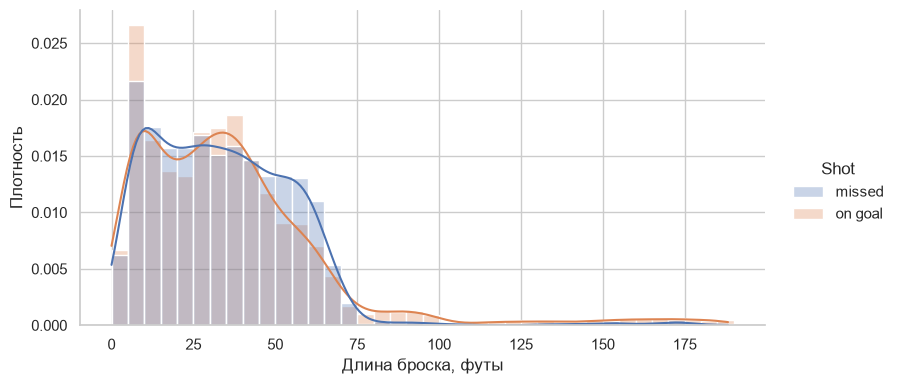

,count,mean,median,max,Long Share
Shot,,,,,
missed,2643,34.014,32.249,185.068,0.011
on goal,4623,36.207,31.828,188.215,0.048


In [10]:
bins = np.arange(0, shots['Shot Length'].max() + 5, 5)
g = sns.displot(
    data=shots, x='Shot Length', hue='Shot', bins=bins,
    stat='density', common_norm=False, kde=True, alpha=0.3,
    height=4, aspect=2
)
g.set_axis_labels('Длина броска, футы', 'Плотность')
plt.show()

shot_stats = shots.groupby('Shot')['Shot Length'].agg(['count', 'mean', 'median', 'max'])
shot_stats['Long Share'] = shots['Shot Length'].gt(89).groupby(shots['Shot']).mean()
display(shot_stats)


Точных бросков 4 623, промахов — 2 643. Для сравнения распределений при разном размере групп используем stat='density' и common_norm=False: высота показывает плотность, а площадь каждой гистограммы отдельно равна единице. Так большая группа не выглядит выше только из-за числа бросков. Интервалы шириной 5 футов общие для обеих групп, а kde=True добавляет сглаженные линии плотности. В таблице Long Share — доля бросков длиннее 89 футов.

**Вывод:** Медианы близки: 31,828 фута у точных бросков и 32,249 у промахов. Дальний хвост у точных бросков выражен сильнее: длиннее 89 футов — около 4,8% точных бросков и 1,1% промахов. Длинный хвост точных бросков, вероятно, связан с дальними выбросами шайбы. Игрок стремится вывести её из своей зоны или направить глубоко в зону соперника. Если шайба летит в створ и вратарь её отражает, событие учитывается как точный бросок даже с большой дистанции. Это объяснение поддерживается сравнением игровых ситуаций: при наличии вратаря в меньшинстве дальними были 35,1% точных бросков, а при равных составах — 4,2%. Доля примерно в 8,4 раза выше.


## 10. Доля бросков в створ за матч


In [11]:
numshots = (
    events.loc[events['Play Type'].isin(all_shot_types)]
    .groupby([G, T, 'Play Type'])
    .size()
    .unstack(fill_value=0)
)
numshots['Shot'] = numshots['shot-on-goal'] + numshots['goal']
numshots['Unblocked'] = numshots['Shot'] + numshots['missed-shot']
numshots['Share of Shots on Goal'] = numshots['Shot'] / numshots['Unblocked']
share = numshots['Share of Shots on Goal']
assert len(numshots) == 2 * len(games), 'Не для каждого матча учтены обе команды'
display(share)


Game ID     Team Making the Play
2025030111  Boston Bruins           0.625
            Buffalo Sabres          0.679
2025030112  Boston Bruins           0.614
            Buffalo Sabres          0.636
2025030113  Boston Bruins           0.694
                                    ...  
2025030414  Vegas Golden Knights    0.583
2025030415  Carolina Hurricanes     0.558
            Vegas Golden Knights    0.510
2025030416  Carolina Hurricanes     0.639
            Vegas Golden Knights    0.595
Name: Share of Shots on Goal, Length: 164, dtype: float64

Группируем события по матчу, команде и типу броска. Метод size() считает события, а unstack(fill_value=0) переносит типы бросков в столбцы и заполняет отсутствующие сочетания нулями. В Shot складываем shot-on-goal и goal, а в Unblocked добавляем missed-shot. Доля попаданий в створ равна Shot / Unblocked; заблокированные броски в знаменатель не входят.

**Вывод:** В среднем около 64% незаблокированных бросков команды за матч попадает в створ. Это среднее по 164 парам «матч — команда».


## 11. Команды с высокой и низкой долей попаданий в створ


In [12]:
avgnumshots = share.groupby(level=T).mean()
print('Пять наибольших средних долей:')
display(avgnumshots.nlargest(5))
print('Пять наименьших средних долей:')
display(avgnumshots.nsmallest(5))


Пять наибольших средних долей:


Team Making the Play
Edmonton Oilers        0.706
Philadelphia Flyers    0.684
Dallas Stars           0.670
Minnesota Wild         0.656
Colorado Avalanche     0.653
Name: Share of Shots on Goal, dtype: float64

Пять наименьших средних долей:


Team Making the Play
Pittsburgh Penguins    0.554
Utah Mammoth           0.599
Carolina Hurricanes    0.615
Tampa Bay Lightning    0.626
Buffalo Sabres         0.626
Name: Share of Shots on Goal, dtype: float64

Для каждой команды усредняем доли попаданий в створ за матч и выбираем пять наибольших и пять наименьших значений. Каждый матч имеет одинаковый вес, независимо от числа бросков.

**Вывод:** Самая высокая средняя доля у Edmonton Oilers — около 70,6%, самая низкая у Pittsburgh Penguins — около 55,4%. Разница между ними — около 15 процентных пунктов.


## 12. Среднее число бросков в створ и голов


In [13]:
avgshots = (
    numshots.groupby(level=T)[['Shot', 'goal']]
    .mean()
    .rename(columns={'goal': 'Goal'})
)
display(avgshots)


Play Type,Shot,Goal
Team Making the Play,,
Anaheim Ducks,31.667,3.250
Boston Bruins,25.167,2.000
Buffalo Sabres,30.462,3.308
Carolina Hurricanes,31.632,3.474
Colorado Avalanche,32.154,3.385
Dallas Stars,31.000,2.500
Edmonton Oilers,28.333,3.500
Los Angeles Kings,25.250,1.250
Minnesota Wild,28.727,3.727


В numshots каждой команде соответствует строка в каждом её матче. Усредняем число бросков в створ и голов по командам. Голы входят в броски в створ, а матчи без голов сохраняются в расчёте.

**Вывод:** Получены средние за матч для всех 16 команд. Больше всего бросков в створ у Colorado Avalanche — около 32,15 за матч, а голов у Minnesota Wild — около 3,73.


## 13. Связь среднего числа бросков и голов


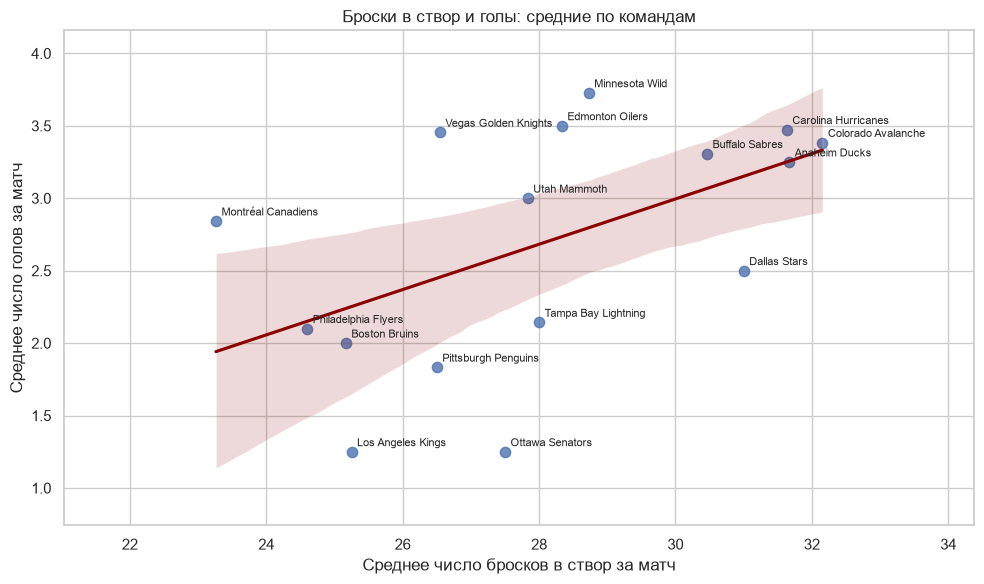

Корреляция Пирсона: 0.521.


In [14]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.regplot(
    data=avgshots, x='Shot', y='Goal', ci=95, seed=0, ax=ax,
    scatter_kws={'s': 55}, line_kws={'color': 'darkred'}
)
for team, row in avgshots.iterrows():
    ax.annotate(team, (row['Shot'], row['Goal']), xytext=(4, 4),
                textcoords='offset points', fontsize=8)
ax.set(xlabel='Среднее число бросков в створ за матч', ylabel='Среднее число голов за матч',
       title='Броски в створ и голы: средние по командам')
ax.margins(x=0.25, y=0.15)
plt.tight_layout()
plt.show()
correlation = avgshots['Shot'].corr(avgshots['Goal'])
print(f'Корреляция Пирсона: {correlation:.3f}.')


Каждая точка — команда: по горизонтали среднее число бросков в створ, по вертикали — среднее число голов за матч. Линия регрессии показывает направление связи, а полоса — 95%-й доверительный интервал её оценки.

**Вывод:** Видна умеренная положительная связь: чаще бросающие в створ команды обычно забивают больше. Корреляция — около 0,521. Разброс заметен: Minnesota Wild забивает в среднем больше, чем Colorado Avalanche, при меньшем числе бросков в створ.


## 14. Матч с наибольшим числом попыток


In [15]:
attempt_counts = events.loc[events['Play Type'].isin(all_shot_types)].groupby(G).size()
max_attempt_ids = attempt_counts.index[attempt_counts.eq(attempt_counts.max())]
idxmax = int(max_attempt_ids[0])
for game_id in max_attempt_ids:
    print(gameInfo(game_id), '— попыток:', int(attempt_counts.loc[game_id]))


Carolina Hurricanes - Ottawa Senators (3 - 2, Final/2OT, 2026-04-20) — попыток: 208


Считаем по матчам все попытки: голы, отражённые, неточные и заблокированные броски. Выводим все игры с максимальным числом попыток; для следующего графика берём первую по ID.

**Вывод:** Максимум — 208 попыток в матче Carolina Hurricanes — Ottawa Senators (3:2, второй овертайм, 20 апреля 2026 г.).


## 15. Броски на площадке


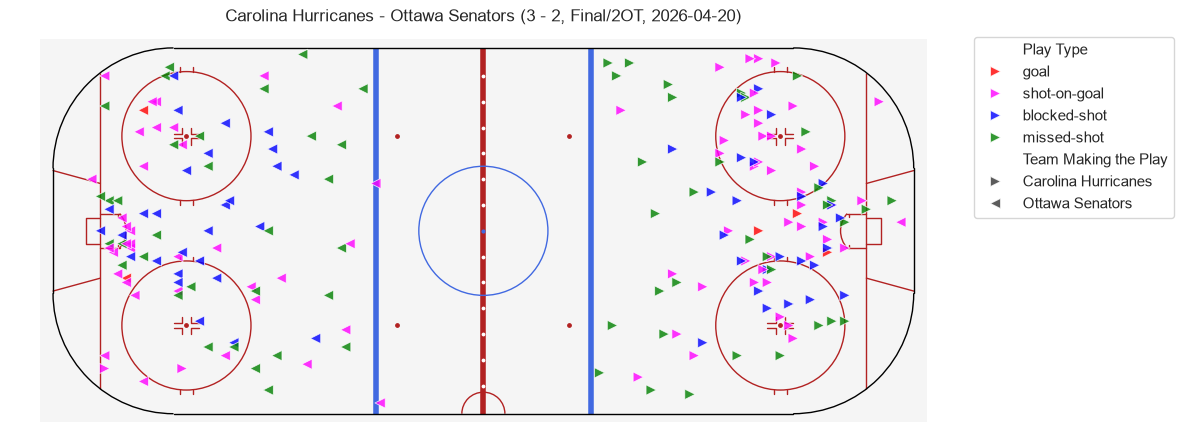

In [16]:
game_shots = events.loc[
    events[G].eq(idxmax) & events['Play Type'].isin(all_shot_types)
].copy()
assert game_shots[[X, Y]].notna().all().all(), 'Нет координат некоторых попыток'

odd = game_shots['Period'] % 2 == 1
assert game_shots[SIDE].eq(np.where(odd, 'right', 'left')).all(), 'Сторона защиты не соответствует правилу поворота по периодам'
game_shots['Plot X'] = np.where(odd, -game_shots[X], game_shots[X])
game_shots['Plot Y'] = np.where(odd, -game_shots[Y], game_shots[Y])

home_team = games.loc[idxmax, 'Home Team']
away_team = games.loc[idxmax, 'Away Team']
colors = {
    'goal': 'red', 'shot-on-goal': 'magenta',
    'blocked-shot': 'blue', 'missed-shot': 'green'
}
fig, ax = plt.subplots(figsize=(12, 6))
plot_rink()
sns.scatterplot(
    data=game_shots, x='Plot X', y='Plot Y',
    hue='Play Type', hue_order=['goal', 'shot-on-goal', 'blocked-shot', 'missed-shot'], palette=colors,
    style=T, style_order=[home_team, away_team],
    markers={home_team: '>', away_team: '<'},
    s=55, alpha=0.8, ax=ax
)
ax.set_aspect('equal', adjustable='box')
ax.axis('off')
ax.set_title(gameInfo(idxmax))
ax.legend(bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout()
plt.show()


Оставляем все попытки найденного матча и рисуем их на площадке из rink.py. В нечётных периодах поворачиваем координаты на 180°: (x, y) → (−x, −y). Это касается и овертаймов: поворачиваем 1-й, 3-й и 5-й периоды, а 2-й и 4-й оставляем исходными. После этого хозяева атакуют вправо и обозначены треугольниками >, гости — влево и обозначены <. Цвет различает исход броска.

**Вывод:** Показаны все 208 попыток матча Carolina Hurricanes — Ottawa Senators (3:2, второй овертайм). Большинство расположено у атакуемых ворот, но есть и дальние броски.


## 16. Десять лучших снайперов


В следующих рейтингах выводим ровно десять игроков. При равных показателях сортируем имена по алфавиту.


In [17]:
goals_events = events.loc[events['Play Type'].eq('goal')]

def rank_players(series, metric):
    table = series.to_frame(metric).rename_axis('Player')
    return table.sort_values([metric, 'Player'], ascending=[False, True]).head(10)

def player_counts_for_types(types):
    players = events.loc[events['Play Type'].isin(types), P1]
    assert players.notna().all(), 'Не указан основной игрок события'
    return players.value_counts()


In [18]:
player_goals = player_counts_for_types(['goal'])
display(rank_players(player_goals, 'Goals'))


,Goals
Player,
Brett Howden,14
Pavel Dorofeyev,12
Logan Stankoven,11
Mitch Marner,10
Jordan Staal,8
Nikolaj Ehlers,8
Alex Newhook,7
Jackson Blake,7
Mark Stone,7


Каждое событие goal добавляет один гол игроку из Player in the Event #1. Подсчитываем появления имён и выбираем десять лидеров.

**Вывод:** Brett Howden забил 14 голов, Pavel Dorofeyev — 12, Logan Stankoven — 11.


## 17. Десять лучших ассистентов


In [19]:
assists_long = goals_events[[P2, P3]].melt(value_name='Player')
player_assists = assists_long['Player'].value_counts()
display(rank_players(player_assists, 'Assists'))


,Assists
Player,
Jack Eichel,20
Mitch Marner,19
Jackson Blake,13
Lane Hutson,13
Martin Necas,12
Nick Suzuki,12
Shea Theodore,12
Taylor Hall,12
Kirill Kaprizov,11


С помощью melt() собираем игроков #2 и #3 из событий goal в одну колонку. Метод value_counts() считает передачи каждого игрока и пропускает пустые значения: у гола может быть до двух передач.

**Вывод:** Больше всего передач у Jack Eichel — 20, затем Mitch Marner — 19.


## 18. Десять лучших по системе «гол плюс пас»


In [20]:
player_points = player_goals.add(player_assists, fill_value=0).astype(int)
display(rank_players(player_points, 'Points'))


,Points
Player,
Mitch Marner,29
Jack Eichel,22
Jackson Blake,20
Taylor Hall,19
Brett Howden,18
Nikolaj Ehlers,18
Shea Theodore,18
Lane Hutson,16
Logan Stankoven,16


Складываем голы и передачи по именам. Параметр fill_value=0 учитывает и тех, у кого есть только голы или только передачи. По сумме выбираем десять лидеров.

**Вывод:** Mitch Marner набрал 29 очков, Jack Eichel — 22, Jackson Blake — 20.


## 19. Среднее число бросков игрока в створ


In [21]:
games_played = player_games.groupby('Player').size().rename('Games')

def per_game_table(types, metric):
    counts = player_counts_for_types(types).reindex(games_played.index, fill_value=0)
    table = pd.DataFrame({'Games': games_played, metric: counts})
    table['Per Game'] = table[metric] / table['Games']
    return table


In [22]:
player_shots = per_game_table(accurate_types, 'Shots on Goal')
top_shooters = player_shots.sort_values(['Per Game', 'Player'], ascending=[False, True]).head(10)
display(top_shooters)


,Games,Shots on Goal,Per Game
Player,,,
Jason Robertson,6,30,5.000
Dylan Guenther,6,27,4.500
Nikita Kucherov,7,31,4.429
Matt Boldy,11,48,4.364
Quinton Byfield,4,17,4.250
Darren Raddysh,7,28,4.000
Joel Eriksson Ek,6,24,4.000
Alex Laferriere,4,15,3.750
David Pastrnak,6,22,3.667


В player_games одна строка на пару «матч — игрок», поэтому size() даёт число игр. Делим суммарное число бросков в створ, включая голы, на все матчи участия игрока — в том числе без бросков. Дополнительный порог по числу матчей условием не задан.

**Вывод:** Лидирует Jason Robertson — 5,0 броска в створ за матч (30 в 6 играх), затем Dylan Guenther — 4,5.


## 20. Среднее число силовых приёмов


In [23]:
player_hits = per_game_table(['hit'], 'Hits')
top_hitters = player_hits.sort_values(['Per Game', 'Player'], ascending=[False, True]).head(10)
display(top_hitters)


,Games,Hits,Per Game
Player,,,
Lawson Crouse,6,38,6.333
Alex Turcotte,1,6,6.000
Alexander Petrovic,1,6,6.000
Yakov Trenin,9,51,5.667
Dylan Cozens,4,22,5.500
Vasily Podkolzin,6,32,5.333
Carl Grundstrom,3,15,5.000
Ivan Barbashev,22,110,5.000
Marcus Foligno,11,55,5.000


В событии hit игрок #1 выполняет силовой приём, а игрок #2 его получает. Учитываем первого и делим число приёмов на все матчи его участия той же функцией, что и для бросков.

**Вывод:** Lawson Crouse выполнял в среднем около 6,33 приёма за матч (38 в 6 играх). У Alex Turcotte и Alexander Petrovic — по 6,0, но каждый сыграл только один матч.


## 21. Вратари без пропущенных голов


In [24]:
def opponent_goalie(rows):
    return rows[AG].where(rows[T].eq(rows['Home Team']), rows[HG])

goalie_games = events.melt(
    id_vars=G, value_vars=[AG, HG], value_name='Goalie'
)[[G, 'Goalie']].dropna().drop_duplicates()
goals_against = (
    goals_events.assign(Goalie=opponent_goalie(goals_events))
    .groupby([G, 'Goalie']).size().rename('Goals Against')
)
goalie_games = goalie_games.join(goals_against, on=[G, 'Goalie']).fillna({'Goals Against': 0})
zero_goalies = goalie_games.loc[goalie_games['Goals Against'].eq(0), 'Goalie'].unique()
display(sorted(zero_goalies))


['Andrei Vasilevskiy',
 'Arturs Silovs',
 'Brandon Bussi',
 'Dan Vladar',
 'Frederik Andersen',
 'Jakub Dobes',
 'Joonas Korpisalo',
 'Scott Wedgewood']

Собираем все пары «матч — вратарь» из обеих колонок вратарей. Функция opponent_goalie() выбирает вратаря соперника: при голе хозяев — вратаря гостей, и наоборот. Считаем пропущенные голы и присоединяем их к таблице участия; отсутствие записанных голов заменяем нулём. Голы по пустым воротам не относятся к конкретному вратарю.

**Вывод:** Ни одного гола хотя бы в одном матче не пропустили восемь вратарей: Andrei Vasilevskiy, Arturs Silovs, Brandon Bussi, Dan Vladar, Frederik Andersen, Jakub Dobes, Joonas Korpisalo и Scott Wedgewood. Учитываются и неполные матчи — только за время участия вратаря.


## 22. Чаще ли броски по пустым воротам заканчиваются голом?


,Attempts,Goals,Goal_Share
Goalie,,,
Пустые ворота,62,25,0.403
С вратарём,7204,461,0.064


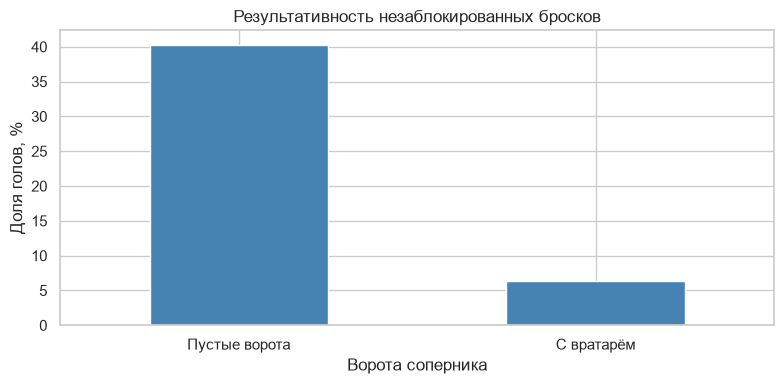

In [25]:
analysis_shots = shots.assign(
    Goalie=np.where(opponent_goalie(shots).isna(), 'Пустые ворота', 'С вратарём'),
    IsGoal=shots['Play Type'].eq('goal')
)
empty_net_summary = analysis_shots.groupby('Goalie').agg(
    Attempts=('IsGoal', 'size'), Goals=('IsGoal', 'sum'), Goal_Share=('IsGoal', 'mean')
)
display(empty_net_summary)

fig, ax = plt.subplots(figsize=(8, 4))
empty_net_summary['Goal_Share'].mul(100).plot.bar(ax=ax, color='steelblue', rot=0)
ax.set(xlabel='Ворота соперника', ylabel='Доля голов, %',
       title='Результативность незаблокированных бросков')
plt.tight_layout()
plt.show()


Для каждого незаблокированного броска определяем вратаря соперника той же функцией, что и в пункте 21. Пустое поле означает пустые ворота. В двух группах считаем попытки, голы и долю голов; на графике доли показаны в процентах.

**Вывод:** По пустым воротам забито 25 голов из 62 попыток — 40,3%. С вратарём — 461 гол из 7 204 попыток, или 6,4%. Разница — 33,92 процентного пункта. В этих данных броски по пустым воротам чаще заканчиваются голом.


### Дополнительно: длина бросков по пустым воротам


In [26]:
distance_data = shots.assign(
    Goalie=np.where(
        opponent_goalie(shots).isna(),
        'Пустые ворота',
        'С вратарём'
    )
)

display(
    distance_data.groupby('Goalie')['Shot Length']
    .agg(['count', 'mean', 'median', 'min', 'max'])
)

far_shots = distance_data.loc[distance_data['Shot Length'].gt(89)]
display(pd.crosstab(far_shots['Shot'], far_shots['Goalie']))


,count,mean,median,min,max
Goalie,,,,,
Пустые ворота,62,86.703,65.475,2.236,187.216
С вратарём,7204,34.967,31.804,0.000,188.215


Goalie,Пустые ворота,С вратарём
Shot,,
missed,23,7
on goal,3,218


Сравниваем расстояния всех незаблокированных бросков по пустым воротам и при наличии вратаря. Первая таблица показывает число бросков, среднее, медиану и диапазон расстояний в футах. Во второй оставлены броски длиннее 89 футов с разделением на точные и промахи.

**Вывод:** По пустым воротам средняя длина составляет 86,70 фута, медиана — 65,48; при наличии вратаря — 34,97 и 31,80 фута соответственно. В среднем броски по пустым воротам заметно длиннее.

Однако дальний хвост именно точных бросков из пункта 9 в основном приходится на попытки при наличии вратаря: 218 из 221, по пустым воротам — только 3. Среди дальних промахов картина другая: 23 из 30 совершены по пустым воротам. Поэтому прежнее объяснение хвоста точных бросков пустыми воротами заменено: большинство таких дальних событий — броски, дошедшие до вратаря и зарегистрированные как shot-on-goal.


### Дополнительно: дальние броски и численный состав

Сравниваем точные броски при наличии вратаря соперника. Численный состав определяем по количеству игроков обеих команд на льду. Дальними считаем броски длиннее 89 футов; Long_Share в таблице показана в процентах.


In [27]:
precise = shots.loc[
    shots['Shot'].eq('on goal') & opponent_goalie(shots).notna()
].copy()

home_shooter = precise[T].eq(precise['Home Team'])
home_players = precise["# of Home Team's Players on the Ice"]
away_players = precise["# of Away Team's Players on the Ice"]

own_players = np.where(home_shooter, home_players, away_players)
opponent_players = np.where(home_shooter, away_players, home_players)

precise['Situation'] = np.select(
    [own_players < opponent_players, own_players > opponent_players],
    ['Меньшинство', 'Большинство'],
    default='Равные составы'
)
precise['Long'] = precise['Shot Length'] > 89

strength_summary = precise.groupby('Situation').agg(
    Shots=('Long', 'size'),
    Long_Shots=('Long', 'sum'),
    Long_Share=('Long', 'mean')
)
strength_summary['Long_Share'] *= 100

display(strength_summary.loc[['Меньшинство', 'Равные составы']])

ratio = (
    strength_summary.loc['Меньшинство', 'Long_Share']
    / strength_summary.loc['Равные составы', 'Long_Share']
)
print(f'В меньшинстве доля дальних бросков выше в {ratio:.1f} раза.')


,Shots,Long_Shots,Long_Share
Situation,,,
Меньшинство,171,60,35.088
Равные составы,3731,156,4.181


В меньшинстве доля дальних бросков выше в 8.4 раза.
